# Exercise 2: Tensors, Derivatives, and Activation Functions (Training)


## Run The Next Cell

The exercises use PyTorch and Matplotlib.


In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)


PyTorch version: 2.5.1+cu124


## Exercise 1: Batched Linear Layer by Hand

Consider a batch of four examples, each with three input features:

```python
X = torch.tensor([
    [ 1.,  2., -1.],
    [ 0., -1.,  2.],
    [ 3.,  1.,  0.],
    [-2.,  1.,  1.]
])
```

A linear layer maps the three input features to two output features using

$$
Z = XW + b,
$$

where $W$ has shape $(3,2)$ and $b$ has shape $(2,)$.

1. Create a weight matrix $W$ and bias $b$ with the values shown in the solution.
2. Compute $Z$ using one matrix multiplication and broadcasting.
3. Explain why the result has shape $(4,2)$.
4. Apply ReLU element-wise to obtain $A$.
5. Count how many activations are exactly zero.
6. Compute the mean activation separately for each output feature.

**Your Solution:**


In [2]:
# ==================== START OF CODE SOLUTION ====================
X = torch.tensor([
    [ 1.,  2., -1.],
    [ 0., -1.,  2.],
    [ 3.,  1.,  0.],
    [-2.,  1.,  1.]
])

W = torch.tensor([
    [ 0.5, -1.0],
    [ 1.0,  0.5],
    [-0.5,  2.0]
])

b = torch.tensor([0.25, -0.75])

Z = X @ W + b
A = torch.relu(Z)

print("X shape:", X.shape)
print("W shape:", W.shape)
print("b shape:", b.shape)
print("Z shape:", Z.shape)
print("\nZ =\n", Z)
print("\nReLU(Z) =\n", A)
print("\nNumber of zero activations:", (A == 0).sum().item())
print("Mean per output feature:", A.mean(dim=0))

# X has shape (4,3) and W has shape (3,2), so X @ W has
# shape (4,2). The bias b has shape (2,) and is broadcast
# across all four rows.
# ===================== END OF CODE SOLUTION =====================


X shape: torch.Size([4, 3])
W shape: torch.Size([3, 2])
b shape: torch.Size([2])
Z shape: torch.Size([4, 2])

Z =
 tensor([[ 3.2500, -2.7500],
        [-1.7500,  2.7500],
        [ 2.7500, -3.2500],
        [-0.2500,  3.7500]])

ReLU(Z) =
 tensor([[3.2500, 0.0000],
        [0.0000, 2.7500],
        [2.7500, 0.0000],
        [0.0000, 3.7500]])

Number of zero activations: 4
Mean per output feature: tensor([1.5000, 1.6250])


## Exercise 2: Manual Softmax with Numerical Stability

Given a batch of logits

```python
logits = torch.tensor([
    [ 2.0,  1.0,  0.1],
    [10.0, 11.0, 12.0],
    [-2.0,  0.0,  2.0]
])
```

implement softmax **without** using `torch.softmax`.

For each row,

$$
p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

However, first subtract the maximum logit in each row:

$$
\tilde{z}_i = z_i - \max_j z_j.
$$

1. Compute the row-wise maxima using `keepdim=True`.
2. Compute the stable softmax probabilities.
3. Verify that every row sums to 1.
4. Compare your result with `torch.softmax(logits, dim=1)`.
5. Explain why subtracting the maximum does not change the final softmax probabilities.

**Your Solution:**


In [3]:
# ==================== START OF CODE SOLUTION ====================
logits = torch.tensor([
    [ 2.0,  1.0,  0.1],
    [10.0, 11.0, 12.0],
    [-2.0,  0.0,  2.0]
])

row_max = logits.max(dim=1, keepdim=True).values
shifted = logits - row_max

exp_logits = torch.exp(shifted)
probs = exp_logits / exp_logits.sum(dim=1, keepdim=True)

print("Row maxima:\n", row_max)
print("\nStable softmax:\n", probs)
print("\nRow sums:", probs.sum(dim=1))
print("\nPyTorch softmax:\n", torch.softmax(logits, dim=1))
print("\nMaximum absolute difference:",
      (probs - torch.softmax(logits, dim=1)).abs().max().item())

# Subtracting the same constant c from every logit in a row gives:
# exp(z_i-c) / sum_j exp(z_j-c)
# = exp(z_i)exp(-c) / [exp(-c)sum_j exp(z_j)]
# = exp(z_i) / sum_j exp(z_j).
# ===================== END OF CODE SOLUTION =====================


Row maxima:
 tensor([[ 2.],
        [12.],
        [ 2.]])

Stable softmax:
 tensor([[0.6590, 0.2424, 0.0986],
        [0.0900, 0.2447, 0.6652],
        [0.0159, 0.1173, 0.8668]])

Row sums: tensor([1.0000, 1.0000, 1.0000])

PyTorch softmax:
 tensor([[0.6590, 0.2424, 0.0986],
        [0.0900, 0.2447, 0.6652],
        [0.0159, 0.1173, 0.8668]])

Maximum absolute difference: 1.4901161193847656e-08


## Exercise 3: Cross-Entropy from Logits Without `torch.nn`

Use the logits from the previous exercise and the class labels

```python
y = torch.tensor([0, 2, 1])
```

For each example, the loss is

$$
L_n = -\log p_{n,y_n}.
$$

1. Compute stable softmax probabilities manually.
2. Use tensor indexing to select the probability assigned to the correct class for each example.
3. Compute the loss for every example.
4. Compute the mean batch loss.
5. Verify your result using `torch.nn.functional.cross_entropy`.

**Your Solution:**


In [4]:
# ==================== START OF CODE SOLUTION ====================
import torch.nn.functional as F

y = torch.tensor([0, 2, 1])

row_max = logits.max(dim=1, keepdim=True).values
shifted = logits - row_max
exp_logits = torch.exp(shifted)
probs = exp_logits / exp_logits.sum(dim=1, keepdim=True)

row_indices = torch.arange(logits.shape[0])
correct_class_probs = probs[row_indices, y]

loss_per_example = -torch.log(correct_class_probs)
mean_loss = loss_per_example.mean()

print("Correct-class probabilities:", correct_class_probs)
print("Loss per example:", loss_per_example)
print("Manual mean loss:", mean_loss)
print("PyTorch mean loss:", F.cross_entropy(logits, y))
# ===================== END OF CODE SOLUTION =====================


Correct-class probabilities: tensor([0.6590, 0.6652, 0.1173])
Loss per example: tensor([0.4170, 0.4076, 2.1429])
Manual mean loss: tensor(0.9892)
PyTorch mean loss: tensor(0.9892)


## Exercise 4: Derive and Verify the Softmax Cross-Entropy Gradient

For one example with logits $z$ and one-hot target $y$, softmax cross-entropy has the important gradient

$$
\frac{\partial L}{\partial z_i} = \hat{y}_i - y_i.
$$

Use

```python
z = torch.tensor([1.2, -0.3, 2.1])
target_class = 2
```

1. Compute the softmax probabilities $\hat{y}$ manually.
2. Construct the one-hot target vector $y$.
3. Compute the gradient analytically as $\hat{y}-y$.
4. Separately create a copy of `z` with `requires_grad=True`.
5. Compute cross-entropy with PyTorch and call `.backward()`.
6. Compare the analytical gradient with the autograd gradient.
7. Report the maximum absolute difference.

**Your Solution:**


In [5]:
# ==================== START OF CODE SOLUTION ====================
z = torch.tensor([1.2, -0.3, 2.1])
target_class = 2

shifted = z - z.max()
exp_z = torch.exp(shifted)
y_hat = exp_z / exp_z.sum()

y_one_hot = torch.zeros_like(z)
y_one_hot[target_class] = 1.0

analytical_gradient = y_hat - y_one_hot

z_auto = z.clone().detach().requires_grad_(True)
loss = F.cross_entropy(
    z_auto.unsqueeze(0),
    torch.tensor([target_class])
)
loss.backward()

print("Softmax probabilities:", y_hat)
print("One-hot target:", y_one_hot)
print("Analytical gradient:", analytical_gradient)
print("Autograd gradient:", z_auto.grad)
print("Maximum absolute difference:",
      (analytical_gradient - z_auto.grad).abs().max().item())
# ===================== END OF CODE SOLUTION =====================


Softmax probabilities: tensor([0.2715, 0.0606, 0.6679])
One-hot target: tensor([0., 0., 1.])
Analytical gradient: tensor([ 0.2715,  0.0606, -0.3321])
Autograd gradient: tensor([ 0.2715,  0.0606, -0.3321])
Maximum absolute difference: 5.960464477539063e-08


## Exercise 5: Two-Layer Neural Network Forward Pass

Implement the forward pass

$$
H = \operatorname{ReLU}(XW_1+b_1),
$$

$$
Z = HW_2+b_2,
$$

$$
P = \operatorname{softmax}(Z).
$$

Requirements:

1. Use a batch of 5 examples with 4 input features.
2. Use 6 hidden units and 3 output classes.
3. Initialize the tensors with a fixed random seed.
4. Do not use `torch.nn.Linear`.
5. Print the shape after every stage.
6. Verify that each probability row sums to 1.
7. Determine the predicted class for every example using `argmax`.

**Your Solution:**


In [6]:
# ==================== START OF CODE SOLUTION ====================
torch.manual_seed(7)

X = torch.randn(5, 4)
W1 = torch.randn(4, 6)
b1 = torch.randn(6)
W2 = torch.randn(6, 3)
b2 = torch.randn(3)

pre_activation = X @ W1 + b1
H = torch.relu(pre_activation)
Z = H @ W2 + b2
P = torch.softmax(Z, dim=1)
predictions = P.argmax(dim=1)

print("X:", X.shape)
print("W1:", W1.shape)
print("pre_activation:", pre_activation.shape)
print("H:", H.shape)
print("W2:", W2.shape)
print("Z:", Z.shape)
print("P:", P.shape)
print("\nProbability row sums:", P.sum(dim=1))
print("Predicted classes:", predictions)
# ===================== END OF CODE SOLUTION =====================


X: torch.Size([5, 4])
W1: torch.Size([4, 6])
pre_activation: torch.Size([5, 6])
H: torch.Size([5, 6])
W2: torch.Size([6, 3])
Z: torch.Size([5, 3])
P: torch.Size([5, 3])

Probability row sums: tensor([1., 1., 1., 1., 1.])
Predicted classes: tensor([2, 1, 2, 0, 2])


## Exercise 6: Manual Backpropagation Through a Linear + ReLU Layer

Consider

$$
Z = XW+b,
\qquad
A=\operatorname{ReLU}(Z),
$$

and suppose a later part of the network gives you an upstream gradient

$$
G_A = \frac{\partial L}{\partial A}.
$$

Using only tensor operations, derive and compute:

$$
G_Z = G_A \odot \operatorname{ReLU}'(Z),
$$

$$
\frac{\partial L}{\partial W}=X^T G_Z,
$$

$$
\frac{\partial L}{\partial b}=\sum_n G_{Z,n},
$$

$$
\frac{\partial L}{\partial X}=G_ZW^T.
$$

Then verify every gradient with PyTorch autograd.

**Your Solution:**


In [7]:
# ==================== START OF CODE SOLUTION ====================
X = torch.tensor([
    [1.0, -2.0, 0.5],
    [0.0,  1.0, 2.0]
])

W = torch.tensor([
    [ 0.5, -1.0],
    [ 1.5,  0.5],
    [-0.5,  2.0]
])

b = torch.tensor([0.2, -0.1])

G_A = torch.tensor([
    [ 1.0, -2.0],
    [ 0.5,  3.0]
])

Z = X @ W + b
relu_mask = (Z > 0).float()
G_Z = G_A * relu_mask

dW = X.T @ G_Z
db = G_Z.sum(dim=0)
dX = G_Z @ W.T

print("Z:\n", Z)
print("\nReLU mask:\n", relu_mask)
print("\nManual dW:\n", dW)
print("Manual db:", db)
print("Manual dX:\n", dX)

# Autograd verification
X_auto = X.clone().detach().requires_grad_(True)
W_auto = W.clone().detach().requires_grad_(True)
b_auto = b.clone().detach().requires_grad_(True)

A_auto = torch.relu(X_auto @ W_auto + b_auto)

# Construct a scalar whose derivative with respect to A is G_A.
L = (A_auto * G_A).sum()
L.backward()

print("\nAutograd dW:\n", W_auto.grad)
print("Autograd db:", b_auto.grad)
print("Autograd dX:\n", X_auto.grad)

print("\ndW matches:", torch.allclose(dW, W_auto.grad))
print("db matches:", torch.allclose(db, b_auto.grad))
print("dX matches:", torch.allclose(dX, X_auto.grad))
# ===================== END OF CODE SOLUTION =====================


Z:
 tensor([[-2.5500, -1.1000],
        [ 0.7000,  4.4000]])

ReLU mask:
 tensor([[0., 0.],
        [1., 1.]])

Manual dW:
 tensor([[0.0000, 0.0000],
        [0.5000, 3.0000],
        [1.0000, 6.0000]])
Manual db: tensor([0.5000, 3.0000])
Manual dX:
 tensor([[ 0.0000,  0.0000,  0.0000],
        [-2.7500,  2.2500,  5.7500]])

Autograd dW:
 tensor([[0.0000, 0.0000],
        [0.5000, 3.0000],
        [1.0000, 6.0000]])
Autograd db: tensor([0.5000, 3.0000])
Autograd dX:
 tensor([[ 0.0000,  0.0000,  0.0000],
        [-2.7500,  2.2500,  5.7500]])

dW matches: True
db matches: True
dX matches: True


## Exercise 7: Finite-Difference Gradient Checking

Autograd gives derivatives automatically, but how can we test whether a gradient is plausible?

For

$$
f(x)=3x^3-2x^2+5x-4,
$$

the analytical derivative is

$$
f'(x)=9x^2-4x+5.
$$

Approximate the derivative numerically using the central-difference formula

$$
f'(x) \approx \frac{f(x+h)-f(x-h)}{2h}.
$$

1. Evaluate the numerical derivative at 100 points between $-3$ and $3$.
2. Try $h=10^{-1},10^{-2},10^{-3},10^{-4}$.
3. For each $h$, compute the maximum absolute error compared with the analytical derivative.
4. Observe how the approximation changes as $h$ becomes smaller.
5. Plot the analytical and numerical derivatives for $h=10^{-3}$.

**Your Solution:**


h=1e-01 -> max absolute error = 0.03001785
h=1e-02 -> max absolute error = 0.00083160
h=1e-03 -> max absolute error = 0.01569366
h=1e-04 -> max absolute error = 0.14230347


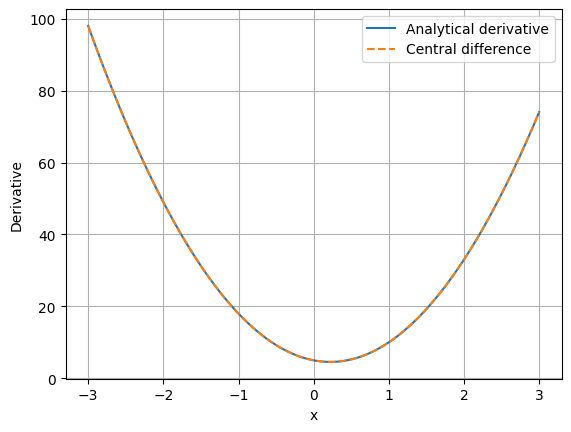

In [8]:
# ==================== START OF CODE SOLUTION ====================
def f_check(x):
    return 3*x**3 - 2*x**2 + 5*x - 4

def f_check_prime(x):
    return 9*x**2 - 4*x + 5

x = torch.linspace(-3, 3, 100)
analytical = f_check_prime(x)

for h in [1e-1, 1e-2, 1e-3, 1e-4]:
    numerical = (f_check(x + h) - f_check(x - h)) / (2 * h)
    max_error = (numerical - analytical).abs().max()
    print(f"h={h:.0e} -> max absolute error = {max_error.item():.8f}")

h = 1e-3
numerical = (f_check(x + h) - f_check(x - h)) / (2 * h)

plt.plot(x, analytical, label="Analytical derivative")
plt.plot(x, numerical, "--", label="Central difference")
plt.xlabel("x")
plt.ylabel("Derivative")
plt.legend()
plt.grid(True)
plt.show()
# ===================== END OF CODE SOLUTION =====================


## Exercise 8: End-to-End Mini Classification Step

Build one complete training step for a tiny multiclass classifier.

1. Create a batch `X` with shape `(6, 4)`.
2. Create integer labels for 3 classes.
3. Create trainable `W` of shape `(4, 3)` and `b` of shape `(3,)`.
4. Compute logits using $XW+b$.
5. Compute cross-entropy loss.
6. Run backpropagation.
7. Print the shapes and norms of `W.grad` and `b.grad`.
8. Perform one gradient-descent update with learning rate $0.1$ inside `torch.no_grad()`.
9. Clear the gradients.
10. Recompute the loss and compare it with the original loss.

This exercise connects tensor algebra, broadcasting, softmax/cross-entropy, gradients, and parameter updates.

**Your Solution:**


In [9]:
# ==================== START OF CODE SOLUTION ====================
torch.manual_seed(42)

X = torch.randn(6, 4)
y = torch.tensor([0, 2, 1, 2, 0, 1])

W = torch.randn(4, 3, requires_grad=True)
b = torch.zeros(3, requires_grad=True)

logits = X @ W + b
loss_before = F.cross_entropy(logits, y)
loss_before.backward()

print("Loss before update:", loss_before.item())
print("W.grad shape:", W.grad.shape)
print("b.grad shape:", b.grad.shape)
print("||W.grad||_2:", torch.linalg.vector_norm(W.grad).item())
print("||b.grad||_2:", torch.linalg.vector_norm(b.grad).item())

learning_rate = 0.1

with torch.no_grad():
    W -= learning_rate * W.grad
    b -= learning_rate * b.grad

W.grad.zero_()
b.grad.zero_()

new_logits = X @ W + b
loss_after = F.cross_entropy(new_logits, y)

print("Loss after one update:", loss_after.item())
print("Loss decreased:", loss_after.item() < loss_before.item())
# ===================== END OF CODE SOLUTION =====================


Loss before update: 1.020933985710144
W.grad shape: torch.Size([4, 3])
b.grad shape: torch.Size([3])
||W.grad||_2: 0.5136570334434509
||b.grad||_2: 0.051341600716114044
Loss after one update: 0.9947522282600403
Loss decreased: True


## Exercise 9: Dealing with Seemingly Non-Differentiable Equations

Not every function used in machine learning is differentiable everywhere. Common examples include the absolute-value function, ReLU, maximum operations, and piecewise functions.

Consider

$$
f(x)=|x|.
$$

For $x\neq 0$,

$$
f'(x)=
\begin{cases}
-1, & x<0,\\
1, & x>0.
\end{cases}
$$

At $x=0$, however, the ordinary derivative does not exist because the left and right derivatives disagree.

This does **not** necessarily prevent us from using such functions in gradient-based machine learning. In practice, several ideas are important:

1. A function may fail to be differentiable only at isolated points.
2. A framework may choose a conventional gradient at such a point.
3. For convex non-differentiable functions, we can often reason using a **subgradient**.
4. Sometimes a hard, non-differentiable operation can be replaced by a smooth approximation.

### Tasks

**A. Absolute value**

1. Create the tensor

```python
x = torch.tensor([-2., -0.5, 0., 0.5, 2.], requires_grad=True)
```

2. Compute

$$
L=\sum_i |x_i|.
$$

3. Call `.backward()` and inspect the gradient chosen by PyTorch.
4. Compare it with the mathematical derivative away from zero.
5. What value does PyTorch use at $x=0$?

**B. ReLU at the kink**

Repeat the experiment for

$$
\operatorname{ReLU}(x)=\max(0,x).
$$

Inspect the gradient at $x=0$.

**C. Subgradients**

For $f(x)=|x|$, the subdifferential at zero is

$$
\partial f(0)=[-1,1].
$$

Explain why choosing $0$ at the non-differentiable point is therefore a valid subgradient choice.

**D. Smooth approximation**

A differentiable approximation to $|x|$ is

$$
f_\varepsilon(x)=\sqrt{x^2+\varepsilon}.
$$

Its derivative is

$$
f_\varepsilon'(x)=\frac{x}{\sqrt{x^2+\varepsilon}}.
$$

For $\varepsilon=10^{-2}$:

1. Evaluate both $|x|$ and $f_\varepsilon(x)$ on points from $-2$ to $2$.
2. Evaluate the smooth derivative.
3. Plot the original function and its smooth approximation.
4. Plot the sign-based derivative of $|x|$ and the smooth derivative.
5. Explain what happens near $x=0$ as $\varepsilon$ becomes smaller.

**E. Think carefully**

Does the fact that a function is non-differentiable at one point mean that gradient-based optimization cannot use it? Explain the distinction between:

- differentiable everywhere,
- differentiable almost everywhere,
- using a subgradient,
- and replacing an operation with a differentiable surrogate.

**Your Solution:**


A. Absolute value
x: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
PyTorch gradient: tensor([-1., -1.,  0.,  1.,  1.])
Expected away from zero: [-1, -1, ?, 1, 1]
PyTorch chooses 0 at x = 0.

B. ReLU
x: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
PyTorch gradient: tensor([0., 0., 0., 1., 1.])
PyTorch chooses 0 at the ReLU kink x = 0.

C. Subgradient
For |x| at x=0, every value in [-1, 1] is a valid subgradient.
Therefore, choosing 0 is a valid subgradient convention.


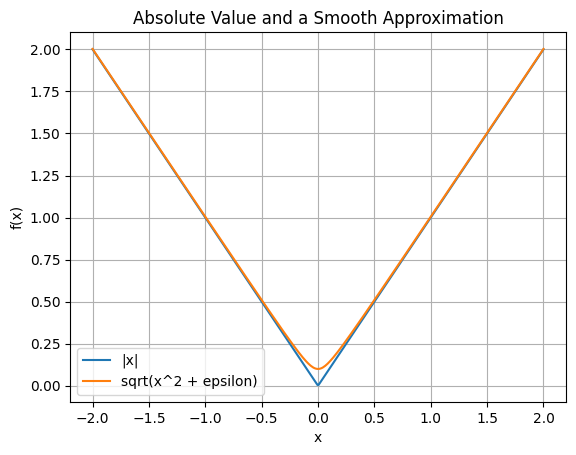

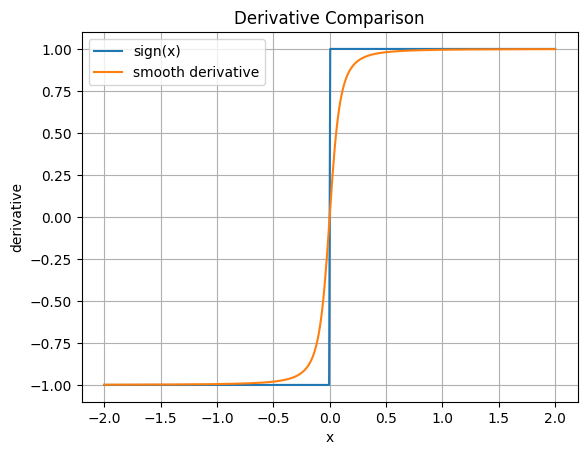


E. Interpretation
A function does not need to be differentiable everywhere to be useful in gradient-based optimization. ReLU and |x| are differentiable almost everywhere. At isolated non-differentiable points, an implementation can use a valid subgradient or another documented convention. If the operation is genuinely unsuitable for gradient propagation, a smooth differentiable surrogate can sometimes be used instead.


In [10]:
# ==================== START OF CODE SOLUTION ====================
# A. Absolute value
x_abs = torch.tensor([-2., -0.5, 0., 0.5, 2.], requires_grad=True)
loss_abs = torch.abs(x_abs).sum()
loss_abs.backward()

print("A. Absolute value")
print("x:", x_abs.detach())
print("PyTorch gradient:", x_abs.grad)
print("Expected away from zero: [-1, -1, ?, 1, 1]")
print("PyTorch chooses 0 at x = 0.")

# B. ReLU
x_relu = torch.tensor([-2., -0.5, 0., 0.5, 2.], requires_grad=True)
loss_relu = torch.relu(x_relu).sum()
loss_relu.backward()

print("\nB. ReLU")
print("x:", x_relu.detach())
print("PyTorch gradient:", x_relu.grad)
print("PyTorch chooses 0 at the ReLU kink x = 0.")

# C. Subgradient explanation
print("\nC. Subgradient")
print("For |x| at x=0, every value in [-1, 1] is a valid subgradient.")
print("Therefore, choosing 0 is a valid subgradient convention.")

# D. Smooth approximation
eps = 1e-2
x = torch.linspace(-2, 2, 400)

abs_y = torch.abs(x)
smooth_y = torch.sqrt(x**2 + eps)

# sign(x) is the derivative of |x| away from zero.
abs_derivative = torch.sign(x)
smooth_derivative = x / torch.sqrt(x**2 + eps)

plt.figure()
plt.plot(x, abs_y, label="|x|")
plt.plot(x, smooth_y, label="sqrt(x^2 + epsilon)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Absolute Value and a Smooth Approximation")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(x, abs_derivative, label="sign(x)")
plt.plot(x, smooth_derivative, label="smooth derivative")
plt.xlabel("x")
plt.ylabel("derivative")
plt.title("Derivative Comparison")
plt.legend()
plt.grid(True)
plt.show()

# E. Main interpretation
print("\nE. Interpretation")
print(
    "A function does not need to be differentiable everywhere to be useful "
    "in gradient-based optimization. ReLU and |x| are differentiable almost "
    "everywhere. At isolated non-differentiable points, an implementation can "
    "use a valid subgradient or another documented convention. If the operation "
    "is genuinely unsuitable for gradient propagation, a smooth differentiable "
    "surrogate can sometimes be used instead."
)
# ===================== END OF CODE SOLUTION =====================
